## Chapter 11 - Using Regression to Test for More Differences with ANOVA and ANCOVA

In this chapter we will learn how to perform ANOVA tests using `ols()` and `anova_lm()`, how to perform post-hoc tests to identify specific differences, how to perform an ANCOVA test, and lastly – how to calculate *p*-values for ANOVA and ANCOVA using the null hypothesis to build a histogram.

In [37]:
%%capture
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf # to use ols()
import statsmodels.api as sm # to format the results of ANOVA
from scipy import stats # for ttest_ind()
import seaborn as sns # to draw graphs
import matplotlib.pyplot as plt # to give us control of the x and y ranges

### Performing ANOVA tests using `ols()` and `anova_lm()`

If we are going to do an ANOVA, then the first thing we need is some data. In this example we will use the recovery times measured for 4 different drugs.

In [38]:
## First, create the data
drug_a = [8, 12, 22]
drug_b = [20, 29, 39]
drug_c = [6, 17, 20]
drug_d = [45, 39, 30]

recovery_time = drug_a + drug_b + drug_c + drug_d
recovery_time

[8, 12, 22, 20, 29, 39, 6, 17, 20, 45, 39, 30]

Now, let's put `recovery_time` into a `data_frame` that uses a factor, `drug`, to organize each measurement. First, let's create the factor `drug`.

In [39]:
## Create a "factor" variable that allows us to keep track of which drug
## is associated with which time in recovery_time
drug = (['a'] * 3) + (['b'] * 3) + (['c'] * 3) + (['d'] * 3)
drug 

['a', 'a', 'a', 'b', 'b', 'b', 'c', 'c', 'c', 'd', 'd', 'd']

In [40]:
df = pd.DataFrame({
    'time': recovery_time,
    'drug': pd.Categorical(drug)
})
df

,time,drug
0,8,a
1,12,a
2,22,a
3,20,b
4,29,b
5,39,b
6,6,c
7,17,c
8,20,c
9,45,d


Now, just like we did for Simple Linear Regression, Multiple Regression, and *t*-tests, we can call the `ols()` and `summary()` functions with the `DataFrame` and simple formula `time ~ drug`.

In [41]:
## Using OLS for ANOVA
model = smf.ols('time ~ drug', data=df)
results = model.fit()
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   time   R-squared:                       0.712
Model:                            OLS   Adj. R-squared:                  0.604
Method:                 Least Squares   F-statistic:                     6.589
Date:                Tue, 17 Nov 2026   Prob (F-statistic):             0.0149
Time:                        11:27:06   Log-Likelihood:                -39.493
No. Observations:                  12   AIC:                             86.99
Df Residuals:                       8   BIC:                             88.93
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     14.0000      4.598      3.045      0.016       3.398      24.602
drug[T.b]     15.3333      6.502      2.358      0.046       0.339      30.327
drug[T.c]      0.3333      6.502      0.051      0.960     -14.661      15.327
drug[T.d]     24.0000      6.502      3.691      0.006       9.006      38.994
==============================================================================
Omnibus:                        2.705   Durbin-Watson:                   2.307
Prob(Omnibus):                  0.259   Jarque-Bera (JB):                0.997
Skew:                          -0.051   Prob(JB):                        0.607
Kurtosis:                       1.591   Cond. No.                         4.79
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

The *p*-value `Prob (F-statistic): 0.0149` tells us to reject the Null Hypothesis that there are no differences in recovery time among the 4 drugs. Now let's see what happens when, instead of calling `summary`, we use the `anova_lm()` function which is specialized for summarizing ANOVA on the same data instead.

In [42]:
sm.stats.anova_lm(results)

,df,sum_sq,mean_sq,F,PR(>F)
drug,3.0,1253.583333,417.861111,6.589137,0.014867
Residual,8.0,507.333333,63.416667,NaN,NaN


We see that the `anova_lm()`function simplifies the output but still gives us the same *F*-value and the same *p*-value, `PR(>F) = 0.014867`.

Now, let's see how we can generate the same *p*-value using the histogram method.

In [43]:
np.random.seed(0)

## To generate random datasets, we'll use a normal distribution.
## This distribution will be based on our observed data, so we
## need to calculate the estimated mean and standard deviation.
overall_mean = df['time'].mean()
overall_sd = df['time'].std()

## Next, we define the number of random datasets we want to create
num_rand_datasets = 10_000
num_datapoints = len(drug_a)

rand_r_squared = np.empty(num_rand_datasets)

## Here is the loop were we create a bunch of random datasets
## with num_datapoints values, perform an ANOVA on each one,
## and then calculate and store the R-squared values.
for i in range(num_rand_datasets):

    r_a = np.random.normal(loc=overall_mean,scale=overall_sd,
                           size=num_datapoints)
    r_b = np.random.normal(loc=overall_mean,scale=overall_sd,
                           size=num_datapoints)
    r_c = np.random.normal(loc=overall_mean,scale=overall_sd,
                           size=num_datapoints)
    r_d = np.random.normal(loc=overall_mean,scale=overall_sd,
                           size=num_datapoints)

    recovery_time_rand = np.concatenate([r_a, r_b, r_c, r_d])

    drug_rand = ((['drug.a'] * num_datapoints) +
                 (['drug.b'] * num_datapoints) +
                 (['drug.c'] * num_datapoints) +
                 (['drug.d'] * num_datapoints))

    data_rand = pd.DataFrame({
        'time': recovery_time_rand,
        'drug': pd.Categorical(drug_rand)
    })

    model = smf.ols('time ~ drug', data=data_rand)
    model_results = model.fit()
    rand_r_squared[i] = model_results.rsquared

Now, let's draw a histogram of the $R^2$ values with the `histplot()` function.

<Axes: ylabel='Count'>

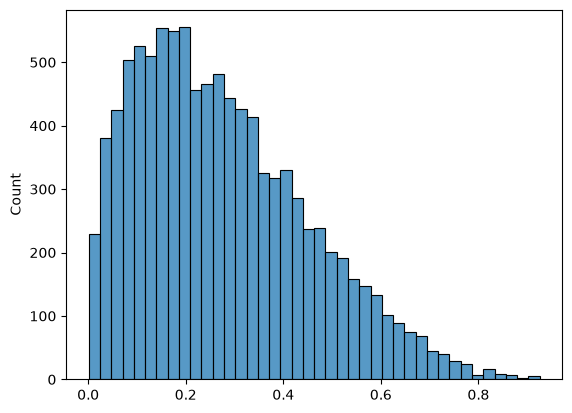

In [44]:
sns.histplot(data=rand_r_squared)

Now, calculate the *p*-value as the percentage of "random" $R^2$ values greater than or equal to the one we got for our original data.

In [45]:
# The number of randomly generated r_squared >= the original r_squared
num_greater = np.sum(rand_r_squared >= results.rsquared)

p_value = num_greater / num_rand_datasets
p_value

np.float64(0.0146)

Thus, the *p*-value calculated with the histogram is the same as that from the ANOVA summary.

Now we have a relativley high confidence that there are differences among the four drugs. The next step is to do pairwise *t*-tests to identify which of the drugs are associated with unequal population mean recovery times. These tests, done after an ANOVA to identify the individual groups that are different, are called **Post-Hoc** tests.

Performing all pairwise *t*-tests in Python is made easy with the `posthoc_ttest()` function. Not only will this function do all of the pairwise *t*-tests for us. It will also adjust the *p*-values using any of the methods that we pass to the `multipletests()` function. We will start by using the Holm correction for multiple testing.

In [46]:
%%capture
# %%capture prevents this cell from printing a ton of STDERR stuff to the screen

## First, check to see if scikit_posthocs is installed, if not, install it.
##
## NOTE: If you **do** need to install something, just know that you may need to
##       restart your session for python to find the new module(s).
##
##       To restart your session:
##       - In Google Colab, click on the "Runtime" menu and select
##         "Restart Session" from the pulldown menu
##       - In a local jupyter notebook, click on the "Kernel" menu and select
##         "Restart Kernel" from the pulldown menu
import pip
try:
  __import__("scikit_posthocs")
except ImportError:
  pip.main(['install', "scikit_posthocs"])

In [47]:
%%capture
import scikit_posthocs as sp

And now, we can run the `posthoc_ttest`.

In [48]:
sp.posthoc_ttest(df,
                 val_col='time',
                 group_col='drug',
                 pool_sd=True,
                 equal_var=True,
                 p_adjust='holm')

,a,b,c,d
a,1.000000,0.184350,0.960371,0.036723
b,0.184350,1.000000,0.184350,0.438551
c,0.960371,0.184350,1.000000,0.036723
d,0.036723,0.438551,0.036723,1.000000


So, the output from `posthoc_ttest()` is a matrix of adjusted *p*-values. The first column are all the adjusted *p*-values associcated with Drug A, starting with itself at the top, and ending with Drug D at the bottom.

The last row has the two adjusted *p*-values less than 0.05, and both of them are associated with Drug D. Drug D appears to be significantly different from Drug A, and Drug C seems to be signficantly different from drug D.

Now let's see what happens when we use False Discovery Rates (FDR) to adjust the *p*-values.

In [49]:
sp.posthoc_ttest(df,
                 val_col='time',
                 group_col='drug',
                 pool_sd=True,
                 equal_var=True,
                 p_adjust='fdr_bh')

,a,b,c,d
a,1.000000,0.074891,0.960371,0.019772
b,0.074891,1.000000,0.074891,0.263131
c,0.960371,0.074891,1.000000,0.019772
d,0.019772,0.263131,0.019772,1.000000


...and the conclusions are the same as before. However, with FDR, the adjusted *p*-values tend to be a little smaller.

### Performing an ANCOVA test

Now, let's learn how to do an ANCOVA in Python. As always, we start by creating our data. In this case, we will use the data of recovery times for two drugs (A, and B), as well as the Height of each person in the trial.

In [50]:
## New data for Drug A, and Drug B
drug_a_time = [6, 9, 12.5, 14]
drug_a_height = [4, 7.5, 10, 12.5]

drug_b_time = [4, 8, 9, 11]
drug_b_height = [5, 11, 12.5, 14]

drug = (['Drug A'] * 4) + (['Drug B'] * 4)

df = pd.DataFrame({
    'time': drug_a_time + drug_b_time,
    'drug': pd.Categorical(drug),
    'height': drug_a_height + drug_b_height 
})

df

,time,drug,height
0,6.0,Drug A,4.0
1,9.0,Drug A,7.5
2,12.5,Drug A,10.0
3,14.0,Drug A,12.5
4,4.0,Drug B,5.0
5,8.0,Drug B,11.0
6,9.0,Drug B,12.5
7,11.0,Drug B,14.0


Now, let's create a plot of the data.

(0.0, 16.0)

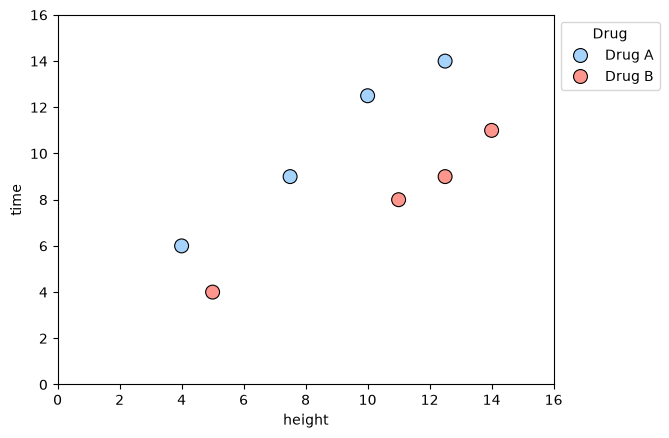

In [51]:
colors = {'Drug A': "#A5D3FC", "Drug B": "#FF968D"}

my_plot = sns.scatterplot(x='height',
                          y='time',
                          data=df,
                          hue='drug',
                          s=100,
                          palette=colors,
                          edgecolor="black")

## Ensure that teh legend is outside of the graph.
sns.move_legend(
    my_plot,
    "upper left",
    bbox_to_anchor=(1,1),
    title="Drug"
)

plt.xlim(0,16)
plt.ylim(0,16)

Now, if we ignore the Height data, we can do a *t*-test on the two drugs, with respect to the recovery times, using the `stats.ttest_ind()` fuction.

In [52]:
stats.ttest_ind(drug_a_time, drug_b_time, equal_var=True)

TtestResult(statistic=np.float64(1.0229256139105145), pvalue=np.float64(0.34580335030295367), df=np.float64(6.0))

The resulting *p*-value is well above 0.05, so without the Height data, we can not reject the Null Hypothesis that the population mean recovery times are equal for the two drugs.

Now, let's see what happens if we ignore the Drug and just use Height to predict recovery time.

In [53]:
model_simple = smf.ols('time ~ height', data=df)
results_simple = model_simple.fit()
results_simple.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   time   R-squared:                       0.551
Model:                            OLS   Adj. R-squared:                  0.477
Method:                 Least Squares   F-statistic:                     7.375
Date:                Tue, 17 Nov 2026   Prob (F-statistic):             0.0348
Time:                        11:27:22   Log-Likelihood:                -17.148
No. Observations:                   8   AIC:                             38.30
Df Residuals:                       6   BIC:                             38.46
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.8449      2.483      1.146      0.295      -3.230       8.920
height         0.6633      0.244      2.716      0.035       0.066       1.261
==============================================================================
Omnibus:                        2.258   Durbin-Watson:                   0.885
Prob(Omnibus):                  0.323   Jarque-Bera (JB):                0.876
Skew:                           0.310   Prob(JB):                        0.645
Kurtosis:                       1.502   Cond. No.                         30.2
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

The *p*-value is less than 0.05, so we can reject the Null Hypothesis that using Height to predict Time is no different from using the average Time. However, this does not tell us if one drug is different from the other, so we need to combine both Height and Drug in a single model. This can be done by adding both column names, separated by a `+` to the **Formula** that we pass to `ols()`.

In [54]:
## NOTE: This only compares fancy, to overall mean
model_fancy = smf.ols('time ~ height + drug', data=df)
results_fancy = model_fancy.fit()
results_fancy.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   time   R-squared:                       0.968
Model:                            OLS   Adj. R-squared:                  0.955
Method:                 Least Squares   F-statistic:                     75.56
Date:                Tue, 17 Nov 2026   Prob (F-statistic):           0.000184
Time:                        11:27:22   Log-Likelihood:                -6.5902
No. Observations:                   8   AIC:                             19.18
Df Residuals:                       5   BIC:                             19.42
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==================================================================================
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept          3.1509      0.728      4.330      0.007       1.280       5.022
drug[T.Drug B]    -4.1810      0.518     -8.064      0.000      -5.514      -2.848
height             0.8499      0.075     11.311      0.000       0.657       1.043
==============================================================================
Omnibus:                        1.752   Durbin-Watson:                   1.809
Prob(Omnibus):                  0.417   Jarque-Bera (JB):                0.859
Skew:                           0.411   Prob(JB):                        0.651
Kurtosis:                       1.620   Cond. No.                         30.3
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

And when we combine both bits of information, the Drug and the Height, we can predict Recovery Time much better than just using the average Recovery Time. But the Recovery Time predictions were also much better when we only used Height, so now the question is...Is using Drug and Height to predict Recovery Time better than just using Height?

One hint at the answer to this question is to compare the Adjusted R-squared values for both tests, and notice that the Adjusted R-squared goes way up for the fancier model. The increase in Adjusted R-squared suggests that using both variables to predict Recovery Time is much better than just using Height. However, we can also calculate a *p*-values to compare the two models directly, using the equation for *F*, and then using *F* to calculate the area under the associated *F*-distribution.

In [55]:
results_simple.ssr

np.float64(34.0787659993436)

In [56]:
results_fancy.ssr

np.float64(2.432967730239305)

In [ ]:
df1 = 1 # 3 - 2 = 1
df2 = 5 # 8 - 3 = 5

F = ((results_simple.ssr - results_fancy.ssr) / df1) / (results_fancy.ssr / df2)
F

np.float64(4.643037583830623)

In [58]:
from scipy.stats import f

1 - f.cdf(x=F, dfn=df1, dfd=df2)

np.float64(0.08373847607130924)

And the resulting *p*-value tells us that using Drug and Height to predict Recovery Time is significantly different from just using Height to predict Recovery Time. And the Adjusted R-square we calculated earlier tells us that the Fancy model is much better.

Now, let's calculate the *p*-value using the Histogram method.

In [ ]:
np.random.seed(0)

mean_time = df['time'].mean()
sd_time = df['time'].std()

mean_height = df['height'].mean()
sd_height = df['height'].std()

num_rand_datasets = 10_000
num_datapoints = len(drug_a_time)

rand_r_squared = np.empty(num_rand_datasets)

for i in range(num_rand_datasets):

    r_a_time = np.random.normal(loc=mean_time, scale=sd_time,
                                size=num_datapoints)
    r_a_height = np.random.normal(loc=mean_height, scale=sd_height,
                                size=num_datapoints)
    r_b_time = np.random.normal(loc=mean_time, scale=sd_time,
                                size=num_datapoints)
    r_b_height = np.random.normal(loc=mean_height, scale=sd_height,
                                size=num_datapoints)

    r_time = np.concatenate([r_a_time, r_b_time])
    r_height = np.concatenate([r_a_height, r_b_height])

    drug_rand = ((['Drug A'] * num_datapoints) +
                 (['Drug B'] * num_datapoints))

    data_rand = pd.DataFrame({
        'time': r_time,
        'drug': pd.Categorical(drug_rand),
        'height': r_height
    })

    simple_model = smf.ols('time ~ height', data=data_rand)
    simple_results = simple_model.fit()
    simple_ssr = simple_results.ssr

    fancy_model = smf.ols('time ~ height + drug', data=data_rand)
    fancy_results = fancy_model.fit()
    fancy_ssr = fancy_results.ssr

    rand_r_squared[i] = (simple_ssr - fancy_ssr) / simple_ssr

<Axes: ylabel='Count'>

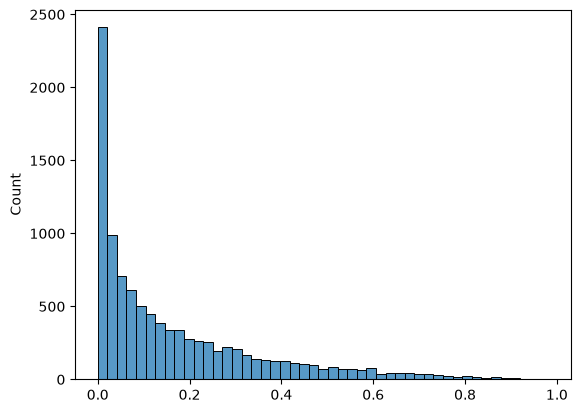

In [60]:
sns.histplot(data=rand_r_squared)

In [63]:
## Calculate the p-value as the percentage of random R-squared values
## greater than or equal to the one we got for our original data.

## The number of randomly generated r-squared >= the original data
observed_partial_r2 = (
    results_simple.ssr - results_fancy.ssr
) / results_simple.ssr

num_greater = np.sum(rand_r_squared >= observed_partial_r2)
p_value = num_greater / num_rand_datasets
p_value

np.float64(0.0008)

And at last, we see that the two *p*-values are essentially the same!